In [1]:
from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ROOT = Path.home() / "mlops"

DATA_PATH = ROOT / "datasets/construction-ppe-small/data.yaml"
MODEL_PATH = ROOT / "yolo11n.pt"
PROJECT_DIR = ROOT / "runs/lab03_notebook"
EXPERIMENT_NAME = "yolo11n_construction_ppe_small"

print("Dataset config exists:", DATA_PATH.exists())
print("Model exists:", MODEL_PATH.exists())

Dataset config exists: True
Model exists: True


In [3]:
model = YOLO(str(MODEL_PATH))

In [4]:
results = model.train(
    data=str(DATA_PATH),
    epochs=10,
    imgsz=416,
    batch=1,
    device="cpu",
    workers=0,
    plots=True,
    project=str(PROJECT_DIR),
    name=EXPERIMENT_NAME,
    exist_ok=True
)

Ultralytics 8.4.215 🚀 Python-3.14.4 torch-2.15.0+cpu CPU (11th Gen Intel Core i7-11370H @ 3.30GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/student/mlops/datasets/construction-ppe-small/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/student/mlops/yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0

In [5]:
run_dir = Path(model.trainer.save_dir)

print("Run directory:", run_dir)
print("Files:")

for item in sorted(run_dir.iterdir()):
    print(item.name)

Run directory: /home/student/mlops/runs/lab03_notebook/yolo11n_construction_ppe_small
Files:
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
args.yaml
confusion_matrix.png
confusion_matrix_normalized.png
labels.jpg
results.csv
results.png
train_batch0.jpg
train_batch1.jpg
train_batch2.jpg
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg
weights


In [6]:
weights_dir = run_dir / "weights"

for item in weights_dir.iterdir():
    print(item.name, round(item.stat().st_size / 1024**2, 2), "MB")

best.pt 5.21 MB
last.pt 5.21 MB


In [7]:
results_csv = run_dir / "results.csv"

df = pd.read_csv(results_csv)
df.columns = df.columns.str.strip()
df

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,69.7771,1.72698,3.92421,1.35428,0.17395,0.07481,0.08076,0.05531,1.56014,3.16402,1.24206,0.000206,0.000206,0.000206
1,2,141.1680,1.61009,3.13125,1.25219,0.27997,0.11310,0.12799,0.08407,1.58255,2.65012,1.22311,0.000374,0.000374,0.000374
2,3,211.9880,1.63584,2.62903,1.19840,0.36773,0.16161,0.17394,0.11492,1.52066,2.29897,1.20614,0.000500,0.000500,0.000500
3,4,281.9260,1.61461,2.48278,1.17838,0.39437,0.21233,0.19130,0.12707,1.43112,2.06587,1.17450,0.000439,0.000439,0.000439
4,5,346.4280,1.56733,2.19770,1.14429,0.28516,0.24822,0.22928,0.13994,1.37069,1.84270,1.13707,0.000378,0.000378,0.000378
5,6,409.0760,1.52193,2.15330,1.14359,0.38558,0.28469,0.25334,0.15383,1.37733,1.80002,1.13547,0.000316,0.000316,0.000316
6,7,473.9410,1.46034,1.90590,1.12859,0.39842,0.33764,0.28533,0.17472,1.34939,1.66119,1.12659,0.000254,0.000254,0.000254
7,8,536.4850,1.42153,1.81421,1.10960,0.42227,0.33879,0.29431,0.18083,1.30349,1.61225,1.11510,0.000192,0.000192,0.000192
8,9,600.3380,1.45156,1.86878,1.09538,0.43061,0.35656,0.31837,0.19943,1.25652,1.50726,1.09274,0.000130,0.000130,0.000130
9,10,665.2930,1.39854,1.75169,1.09147,0.44755,0.36636,0.32251,0.20350,1.25370,1.50176,1.09379,0.000068,0.000068,0.000068


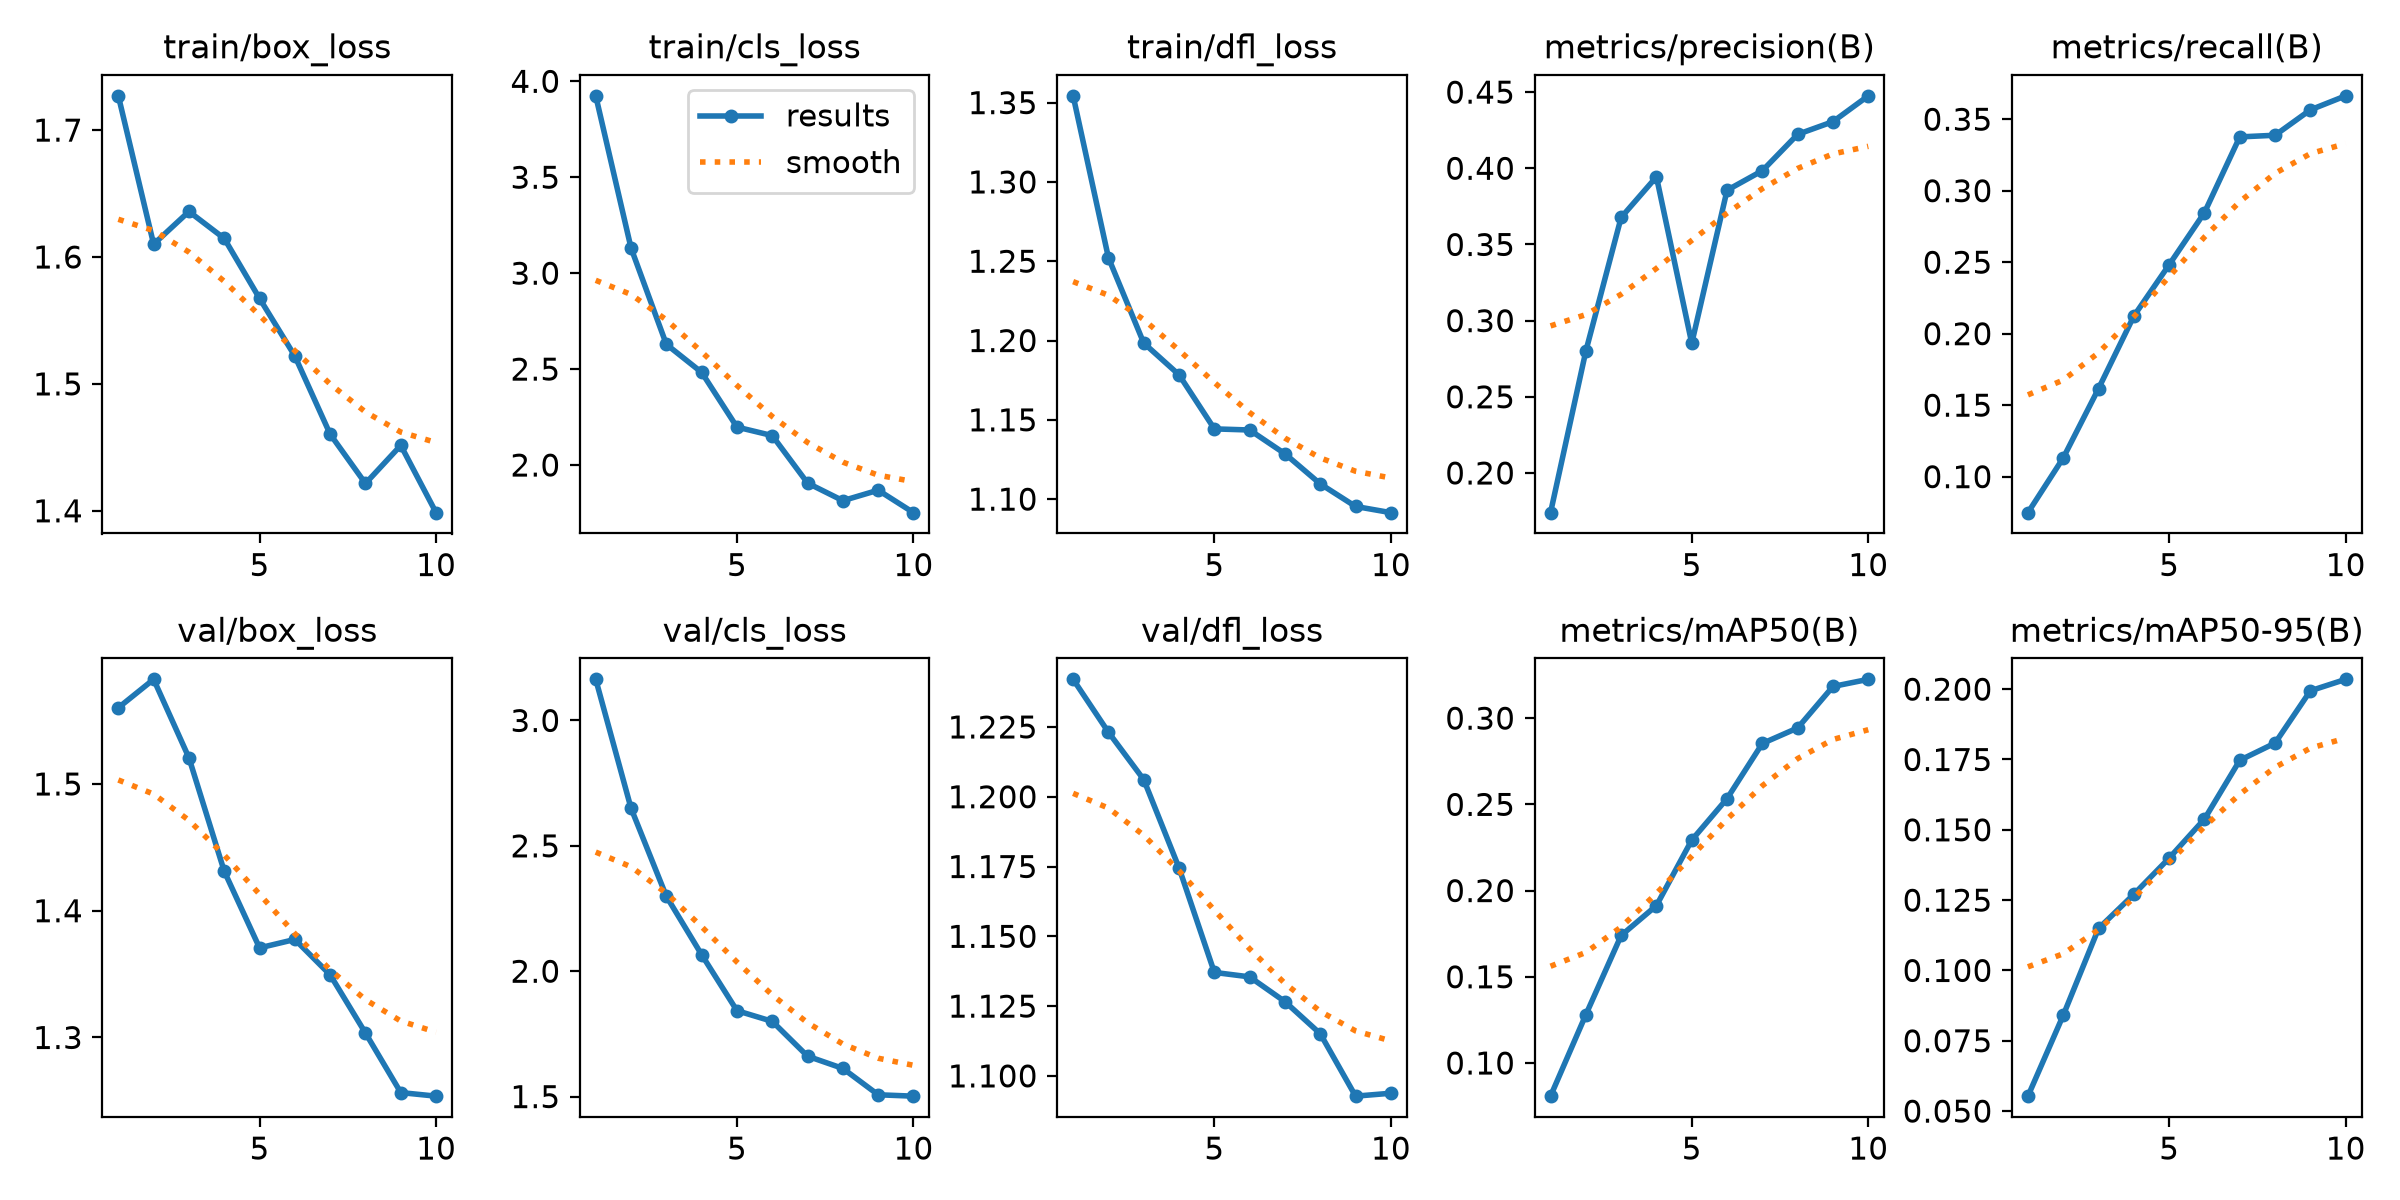

In [8]:
from IPython.display import display, Image

display(Image(filename=str(run_dir / "results.png")))

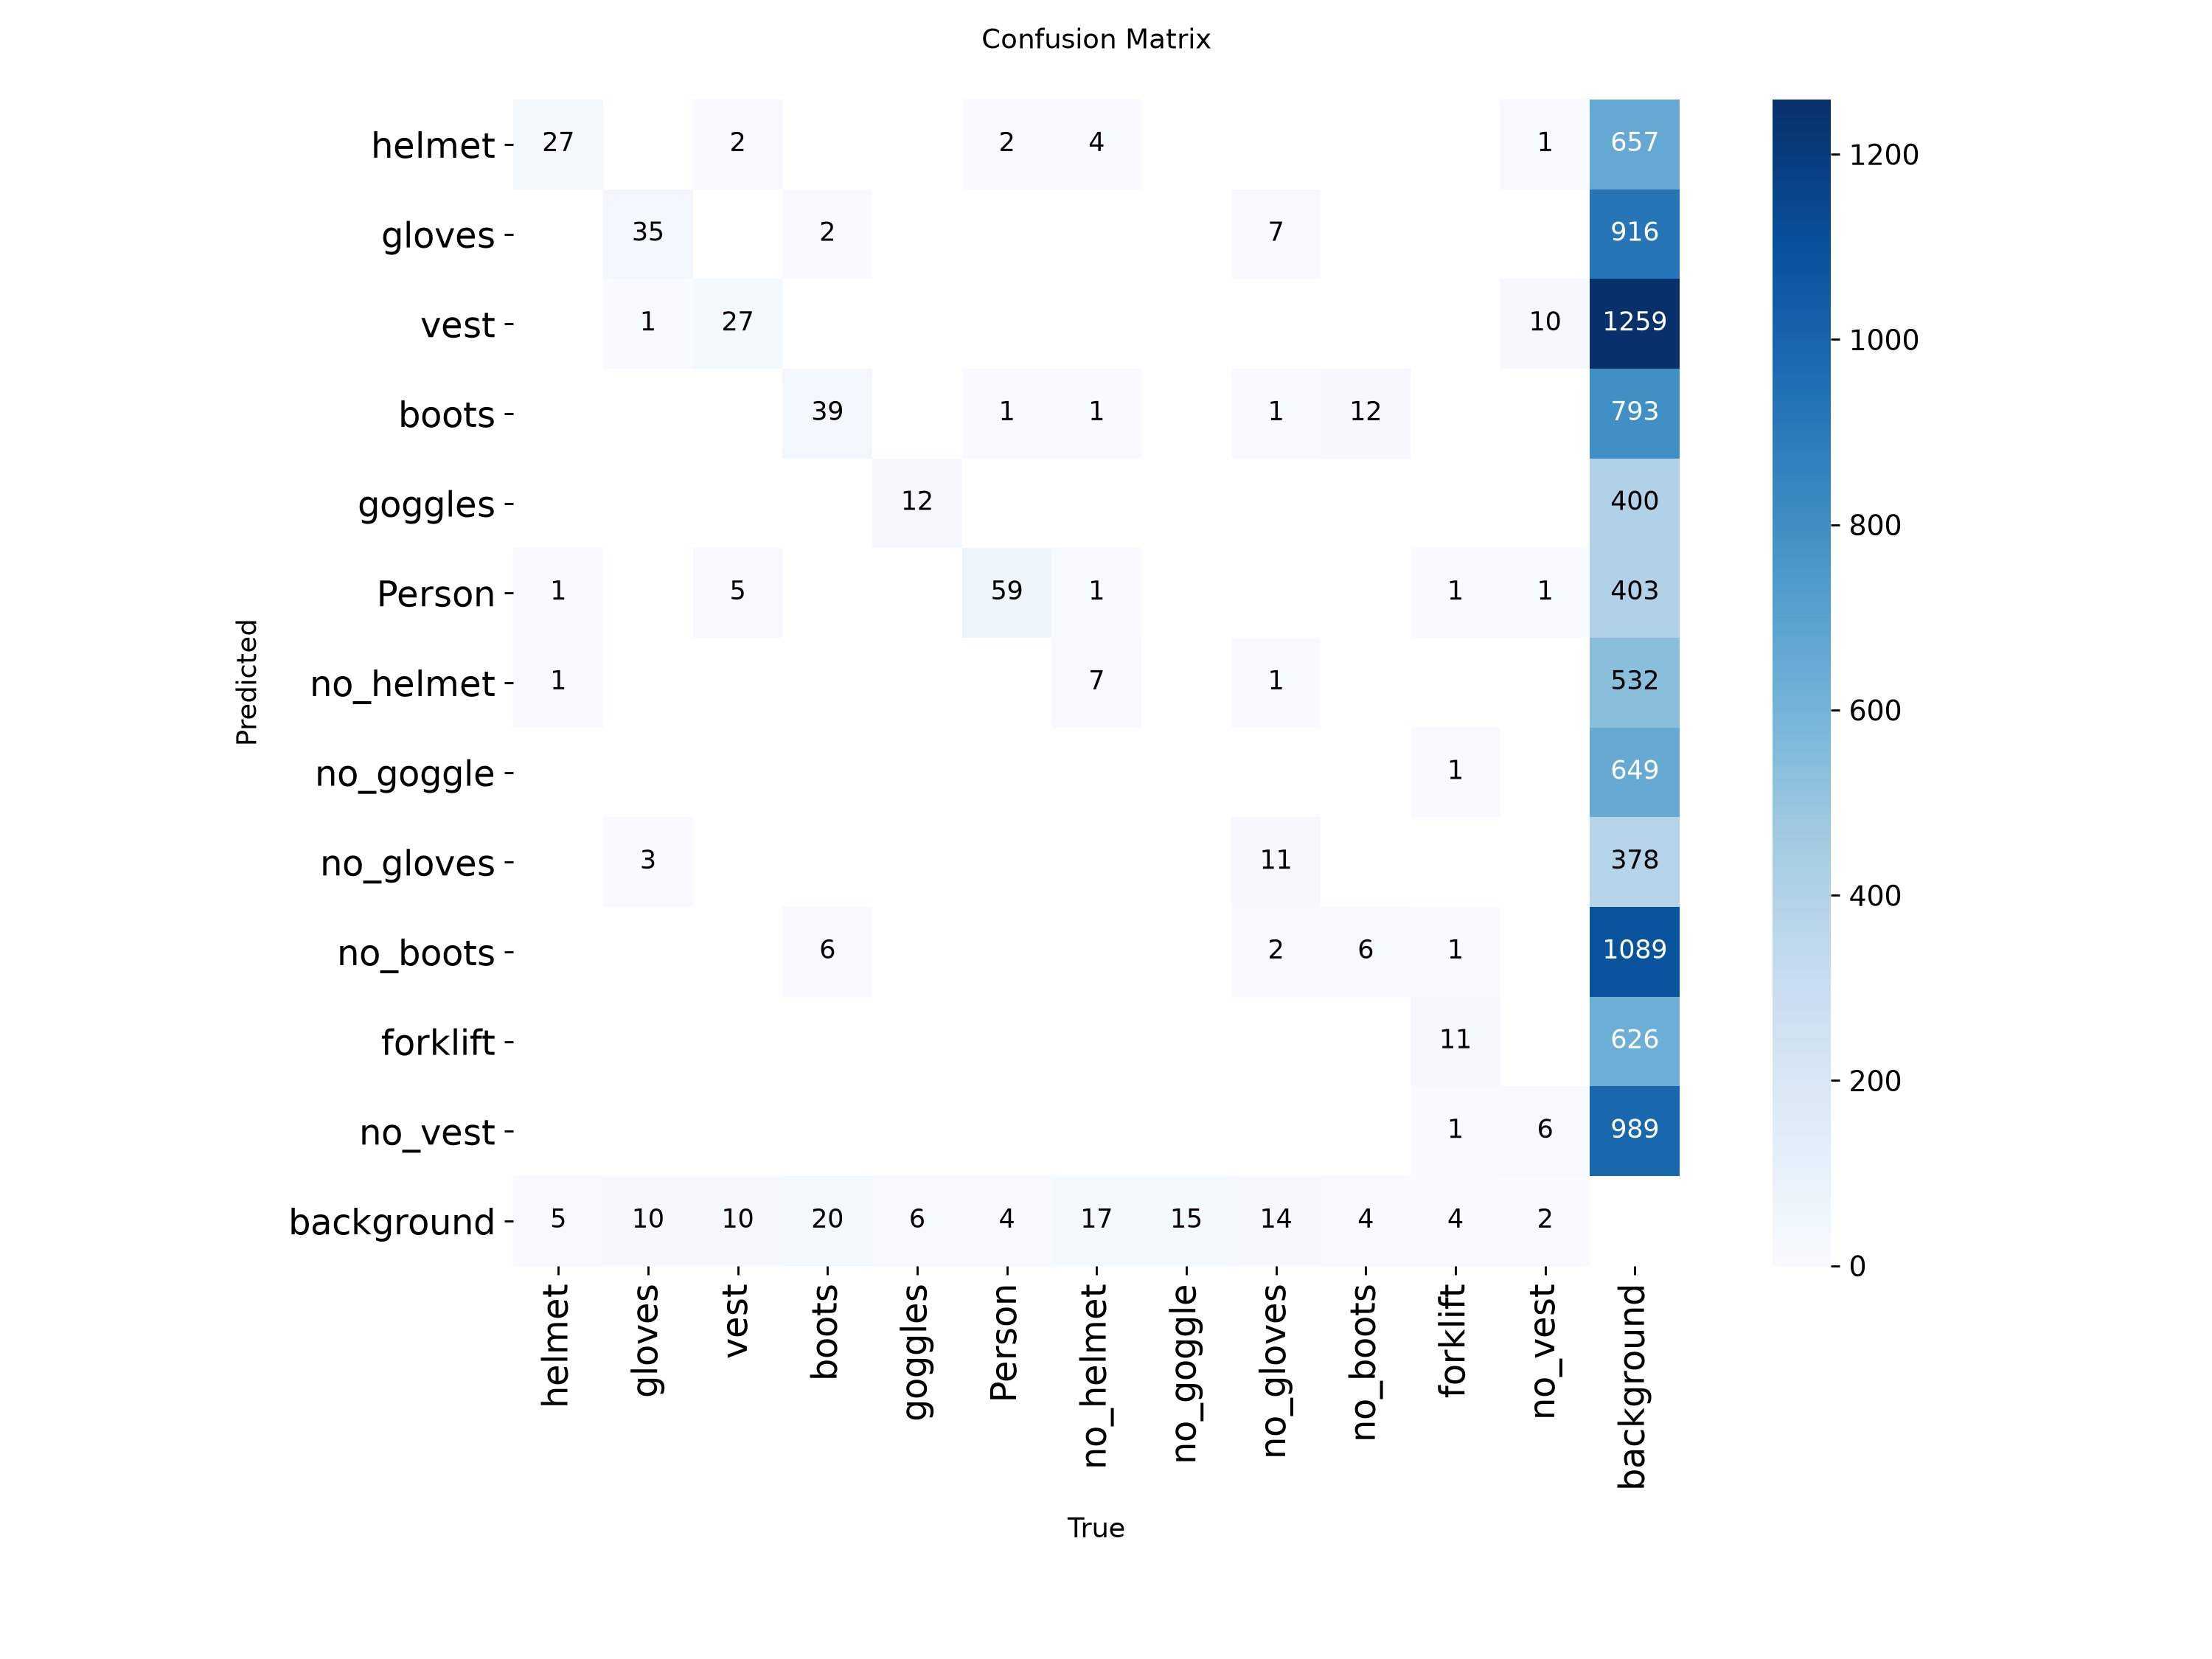

In [9]:
display(Image(filename=str(run_dir / "confusion_matrix.png")))